Implement K-Means clustering/ hierarchical clustering on sales_data_sample.csv dataset.  Determine the number of clusters using the elbow method.  Dataset link : https://www.kaggle.com/datasets/kyanyoga/sample-sales-data

In [1]:
!pip install pandas numpy matplotlib scikit-learn scipy

Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


First five rows:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abb

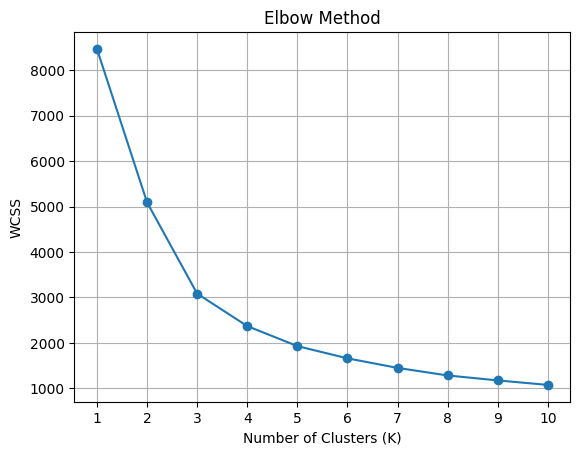


K-Means cluster counts:
KMeans_Cluster
0     881
1     907
2    1035
Name: count, dtype: int64


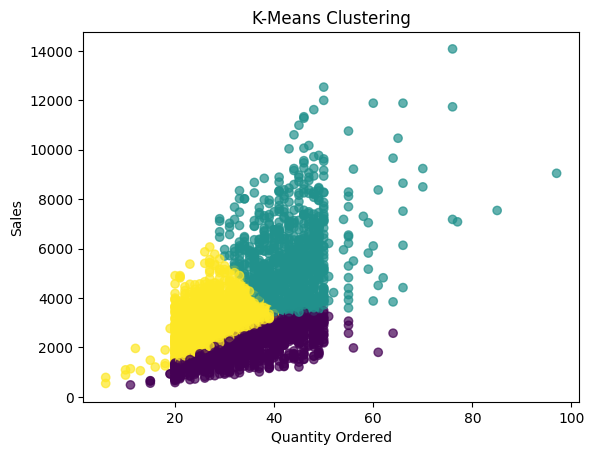


Hierarchical cluster counts:
Hierarchical_Cluster
0    1014
1     685
2    1124
Name: count, dtype: int64


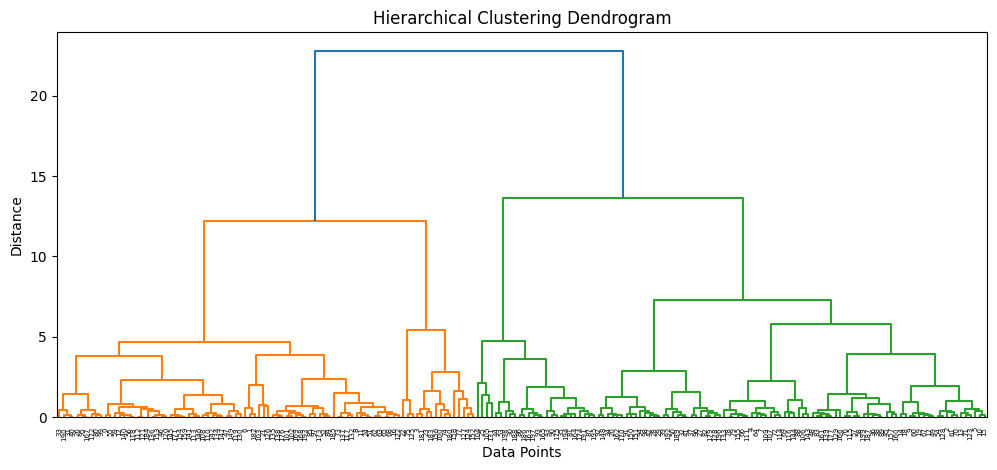

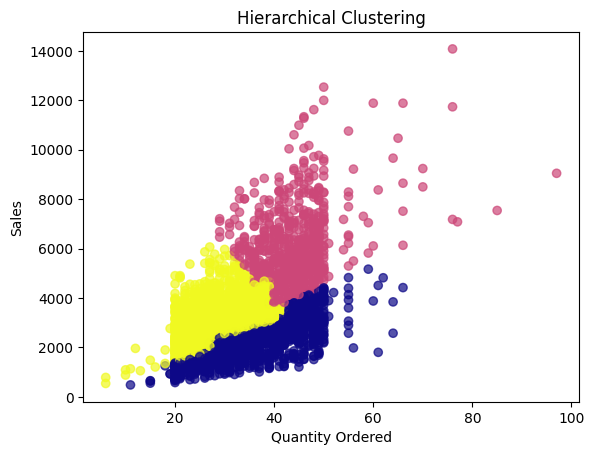


Final results:
   QUANTITYORDERED  PRICEEACH    SALES  KMeans_Cluster  Hierarchical_Cluster
0               30      95.70  2871.00               2                     2
1               34      81.35  2765.90               2                     2
2               41      94.74  3884.34               1                     1
3               45      83.26  3746.70               1                     0
4               49     100.00  5205.27               1                     1
5               36      96.66  3479.76               2                     2
6               29      86.13  2497.77               2                     2
7               48     100.00  5512.32               1                     1
8               22      98.57  2168.54               2                     2
9               41     100.00  4708.44               1                     1


In [2]:

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Step 1: Read dataset
df = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

# Step 2: Select numerical features
features = ["QUANTITYORDERED", "PRICEEACH", "SALES"]
X = df[features].copy()

# Handle missing values
X = X.fillna(X.median())

# Step 3: Normalize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Find optimal clusters using Elbow Method
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot Elbow curve
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

# Step 5: Apply K-Means
# Select K by observing the elbow plot
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print("\nK-Means cluster counts:")
print(df["KMeans_Cluster"].value_counts().sort_index())

# Step 6: Visualize K-Means clusters
plt.scatter(
    df["QUANTITYORDERED"],
    df["SALES"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("K-Means Clustering")
plt.show()

# Step 7: Hierarchical Clustering
hierarchical = AgglomerativeClustering(n_clusters=optimal_k)
df["Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)

print("\nHierarchical cluster counts:")
print(df["Hierarchical_Cluster"].value_counts().sort_index())

# Step 8: Plot dendrogram using a sample for readability
sample_size = min(200, len(X_scaled))
sample = X_scaled[:sample_size]

linked = linkage(sample, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()

# Step 9: Visualize hierarchical clusters
plt.scatter(
    df["QUANTITYORDERED"],
    df["SALES"],
    c=df["Hierarchical_Cluster"],
    cmap="plasma",
    alpha=0.7
)

plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.title("Hierarchical Clustering")
plt.show()

# Step 10: Display sample results
print("\nFinal results:")
print(df[features + ["KMeans_Cluster", "Hierarchical_Cluster"]].head(10))
